# 06 — Backtesting Strategy

**Goal:** Convert walk-forward model predictions into trading signals, simulate a portfolio with realistic transaction costs, and report risk-adjusted performance metrics.

**Signal logic:** long if prediction > 0, short if prediction < 0, flat at threshold.  
**Costs:** 5 bps per unit of turnover.  
**Portfolio:** equal-weight across assets, daily rebalancing on signal changes.

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from src.config import DATA_PROCESSED_DIR
from src.backtesting.performance import compute_strategy_returns, summarize_performance
from src.backtesting.portfolio import equal_weight_portfolio
from src.models.evaluation import sharpe_ratio, max_drawdown, information_coefficient, hit_rate
from src.risk.drawdown import drawdown_series
from src.risk.var_cvar import historical_var, historical_cvar

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

COST_BPS = 5.0
FOCUS_MODEL = "XGBoost (full)"

## 1. Load walk-forward predictions

In [2]:
wf = pd.read_parquet(DATA_PROCESSED_DIR / "backtest_results.parquet")
wf["date"] = pd.to_datetime(wf["date"])

models = wf["model"].unique()
tickers = sorted(wf["ticker"].unique())
print(f"Models: {list(models)}")
print(f"Tickers: {tickers}")
print(f"Date range: {wf['date'].min().date()} → {wf['date'].max().date()}")

Models: ['Ridge (price)', 'Ridge (full)', 'XGBoost (price)', 'XGBoost (full)', 'LightGBM (full)']
Tickers: ['CORN', 'DBA', 'GLD', 'SOYB', 'UNG', 'USO', 'WEAT']
Date range: 2007-03-27 → 2026-04-21


## 2. Per-asset strategy returns — all models

In [3]:
all_strat = {}
summary_rows = []

for model_name in models:
    sub = wf[wf["model"] == model_name].copy()
    strat_frames = []
    for tkr in tickers:
        t = sub[sub["ticker"] == tkr].sort_values("date").dropna(subset=["prediction","actual"])
        if t.empty:
            continue
        t = compute_strategy_returns(t, cost_bps=COST_BPS)
        t["ticker"] = tkr
        strat_frames.append(t)
        s = summarize_performance(t, cost_bps=COST_BPS)
        s["ticker"] = tkr
        s["model"]  = model_name
        summary_rows.append(s)

    all_strat[model_name] = pd.concat(strat_frames, ignore_index=True)

summary = pd.DataFrame(summary_rows)
focus = summary[summary["model"] == FOCUS_MODEL].set_index("ticker")
print(f"=== {FOCUS_MODEL} — Per-asset performance ===")
print(focus[["sharpe_net","max_drawdown","hit_rate","ic","avg_turnover","total_net_return"]].round(3).to_string())

=== XGBoost (full) — Per-asset performance ===
        sharpe_net  max_drawdown  hit_rate     ic  avg_turnover  total_net_return
ticker                                                                           
CORN         0.310        -0.757     0.504  0.046         0.365             0.511
DBA          0.602        -0.787     0.532  0.061         0.356             3.586
GLD          1.384        -0.901     0.550  0.113         0.360           312.029
SOYB         1.222        -0.629     0.534  0.121         0.376            24.296
UNG         -0.474        -1.000     0.498 -0.005         0.383            -1.000
USO          0.425        -0.999     0.513  0.021         0.344             0.038
WEAT        -0.115        -0.998     0.504  0.029         0.332            -0.882


## 3. Equal-weight portfolio equity curve

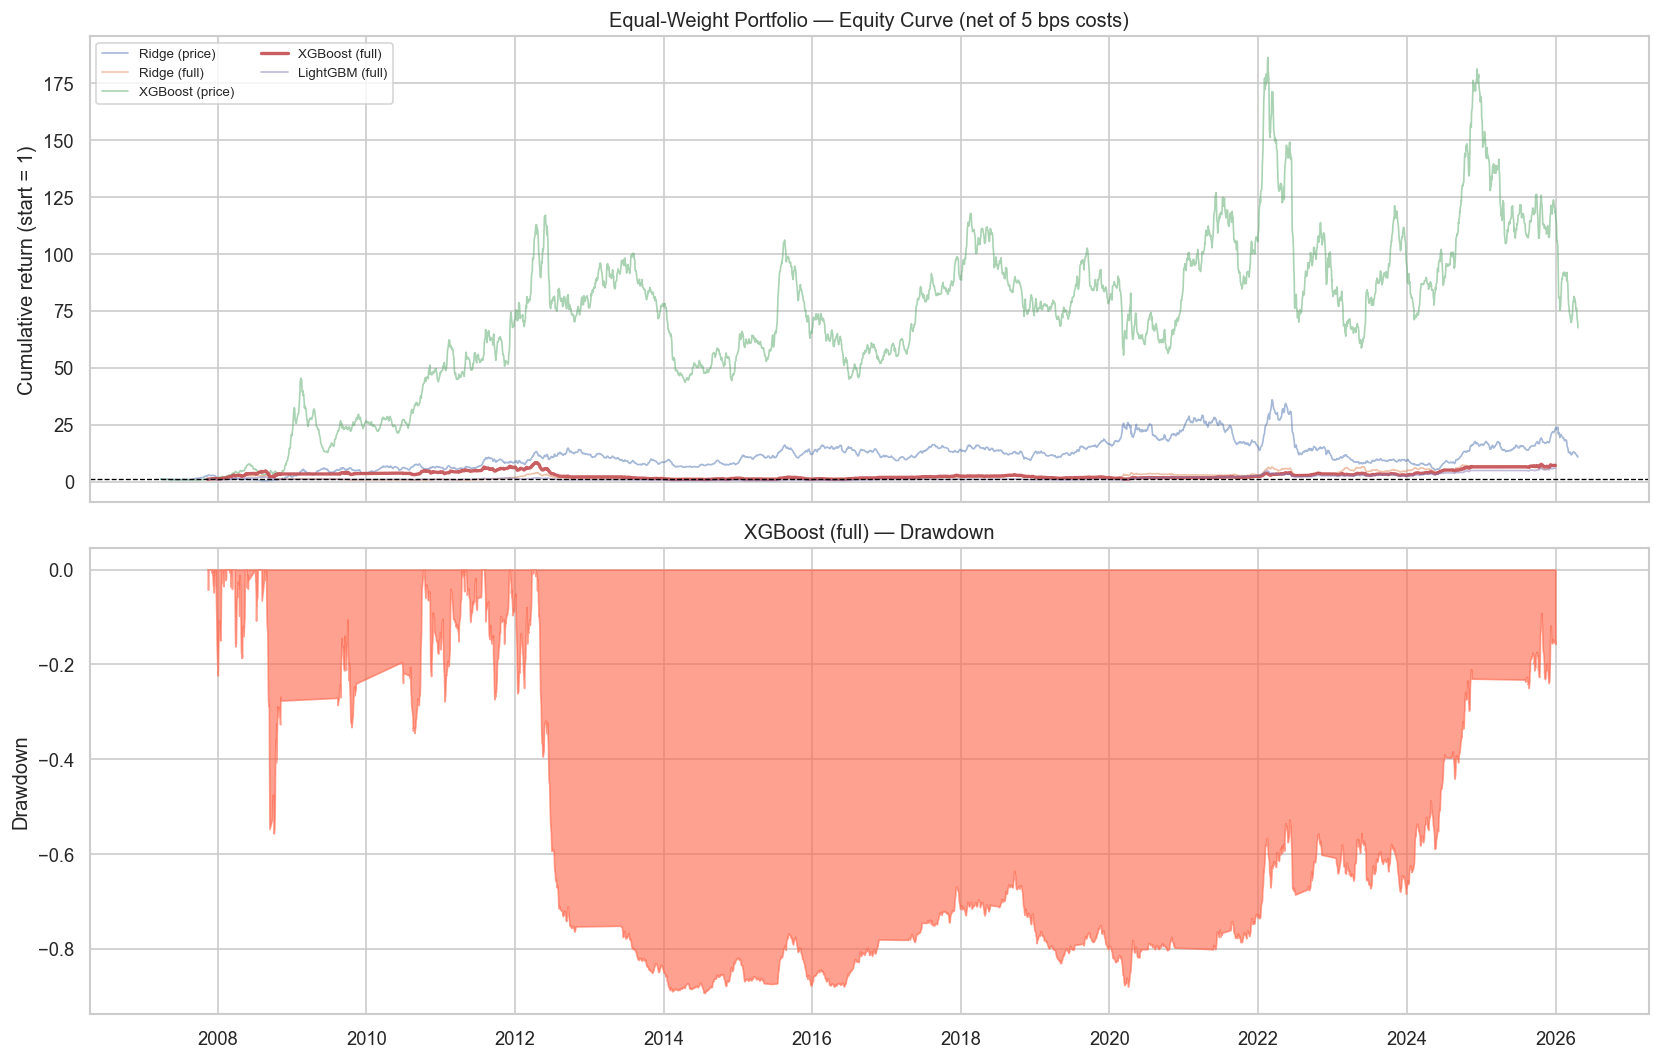

In [4]:
portfolios = {}
for model_name in models:
    strat = all_strat[model_name].copy()
    port = equal_weight_portfolio(strat, cost_bps=0)   # costs already in net_return
    # Rebuild equity from net_return column already computed
    daily = (strat.groupby("date")["net_return"].mean()
             .reset_index().rename(columns={"net_return": "portfolio_return"}))
    daily["equity_curve"] = (1 + daily["portfolio_return"]).cumprod()
    portfolios[model_name] = daily

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# Equity curves
for model_name, port in portfolios.items():
    lw = 2 if FOCUS_MODEL in model_name else 1
    alpha = 0.9 if FOCUS_MODEL in model_name else 0.5
    axes[0].plot(port["date"], port["equity_curve"],
                 label=model_name, lw=lw, alpha=alpha)
axes[0].axhline(1, color="black", lw=0.8, ls="--")
axes[0].set_title("Equal-Weight Portfolio — Equity Curve (net of 5 bps costs)")
axes[0].set_ylabel("Cumulative return (start = 1)")
axes[0].legend(fontsize=8, ncol=2)

# Drawdown of best model
focus_port = portfolios[FOCUS_MODEL]
dd = drawdown_series(focus_port["equity_curve"])
axes[1].fill_between(focus_port["date"], dd, 0, alpha=0.6, color="tomato")
axes[1].set_title(f"{FOCUS_MODEL} — Drawdown")
axes[1].set_ylabel("Drawdown")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.savefig("../reports/figures/equity_curve.png", dpi=150)
plt.show()

## 4. Drawdown figure and risk metrics

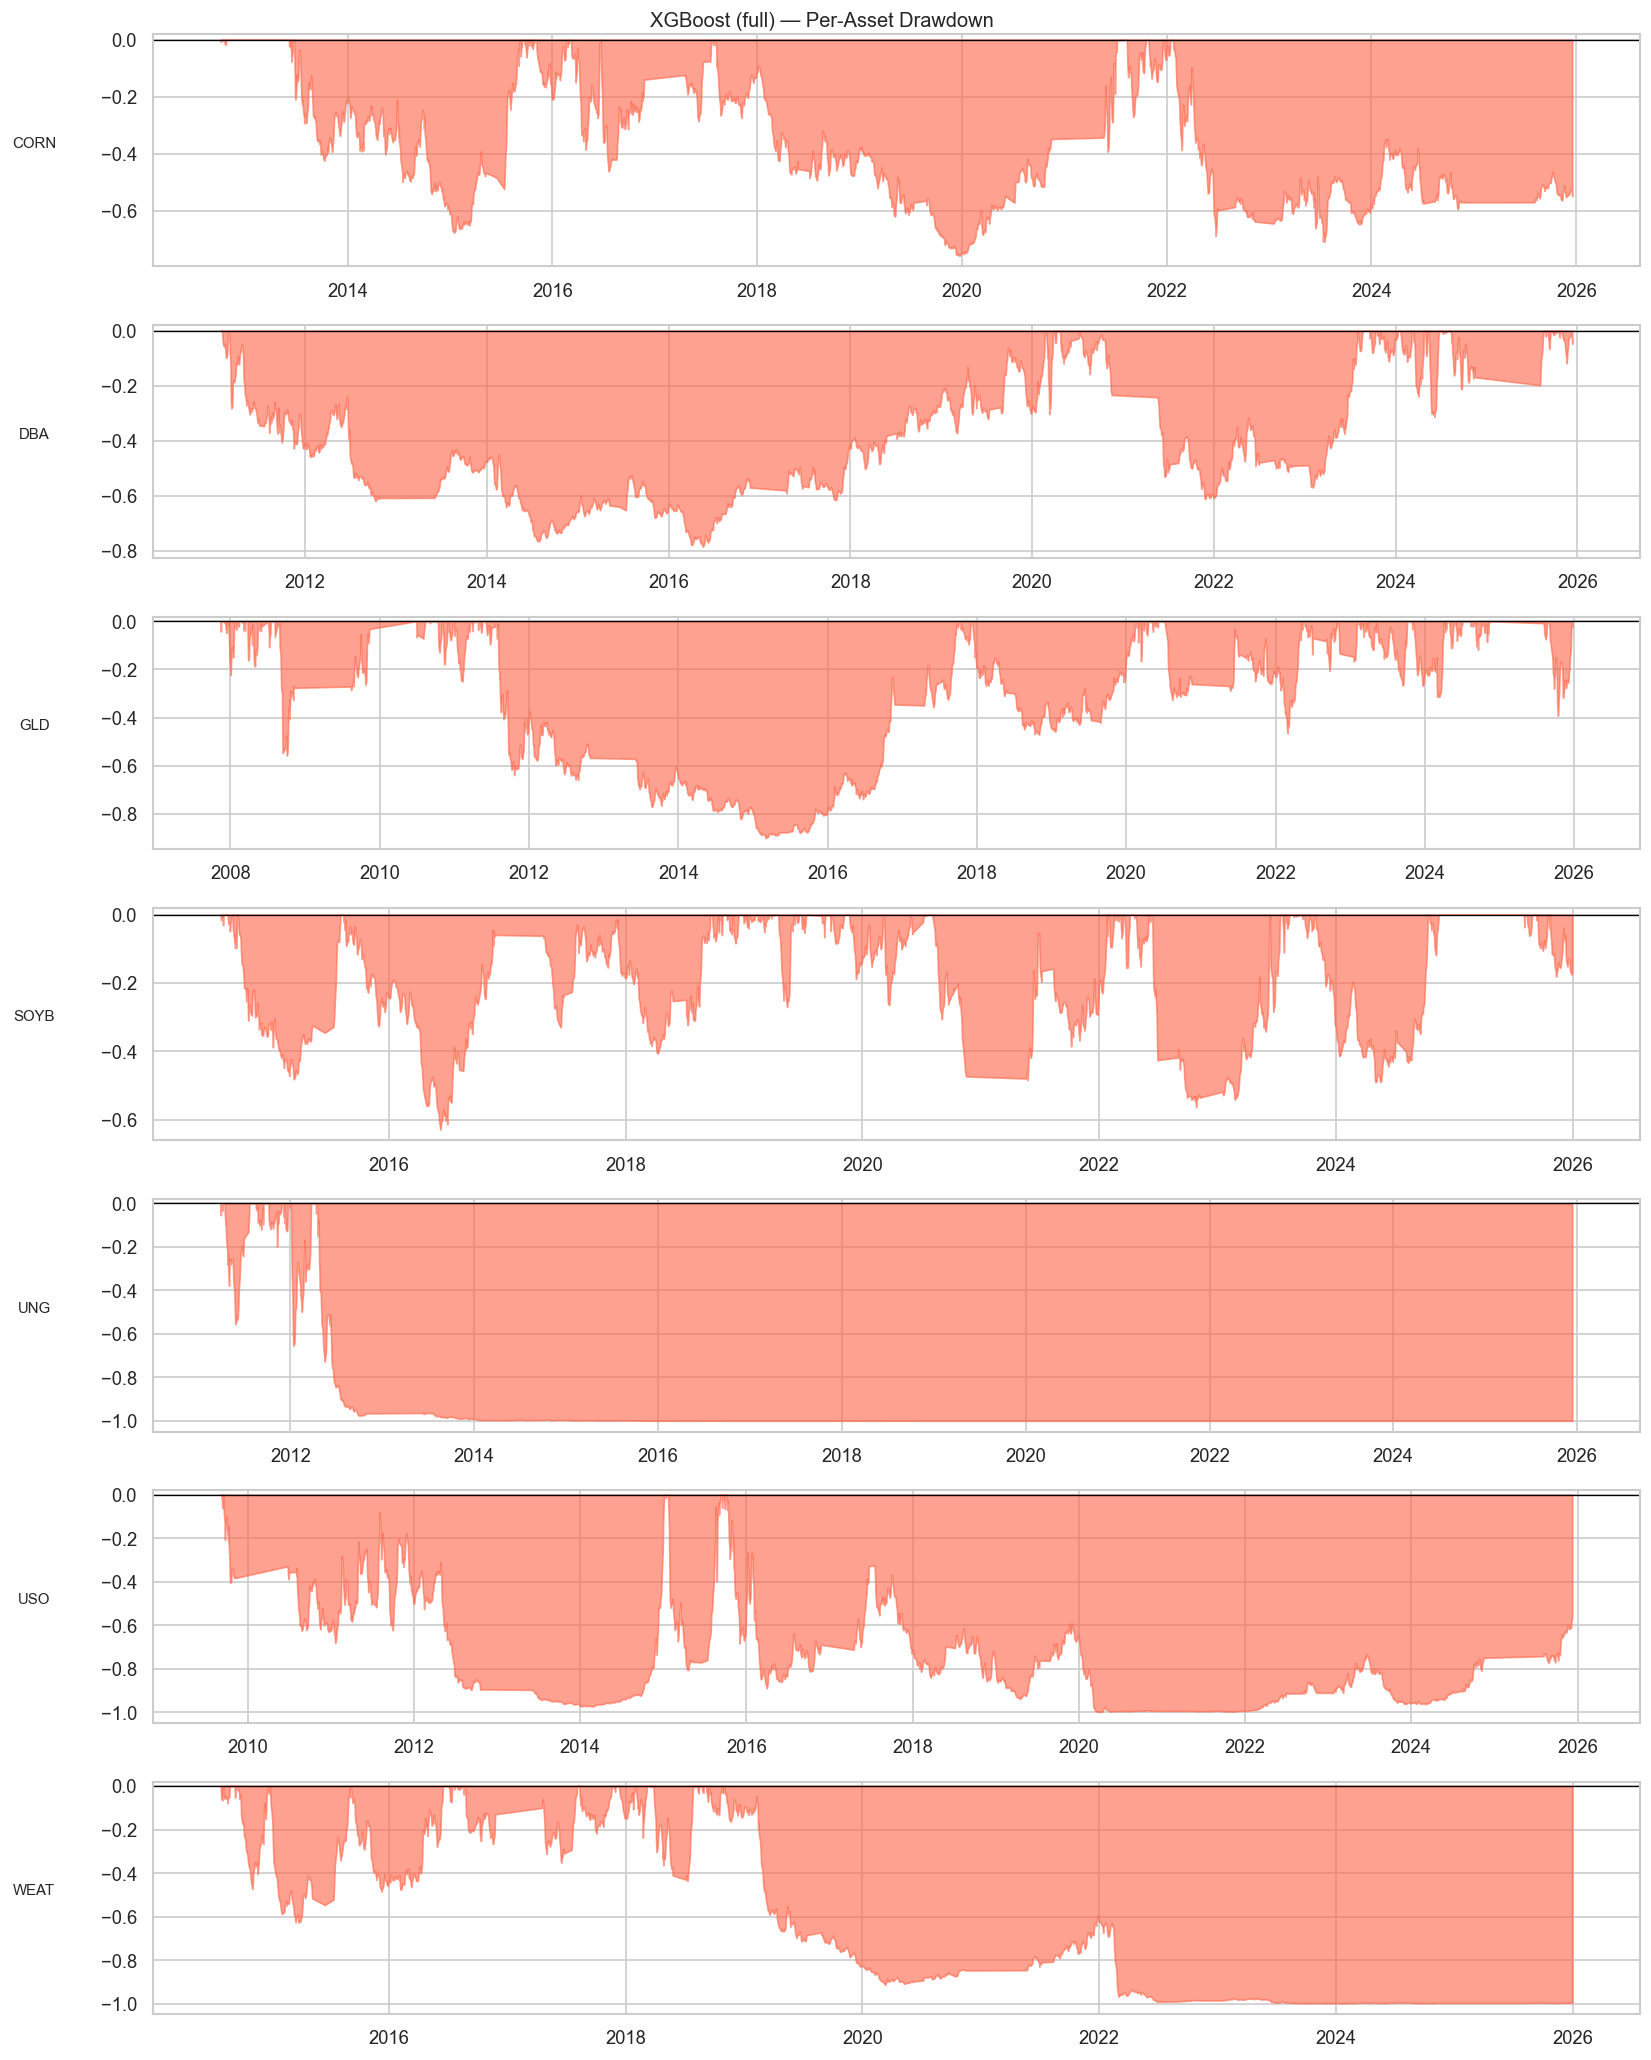

,sharpe_net,max_dd,VaR_95,CVaR_95,ann_return,avg_turnover
ticker,,,,,,
CORN,0.310,-0.7566,-0.0401,-0.0575,0.1296,0.3651
DBA,0.602,-0.7869,-0.0292,-0.0398,0.1783,0.3561
GLD,1.384,-0.9009,-0.0349,-0.0507,0.5145,0.3598
SOYB,1.222,-0.6285,-0.0346,-0.0462,0.4418,0.3759
UNG,-0.474,-1.0000,-0.1124,-0.1486,-0.5057,0.3827
USO,0.425,-0.9989,-0.0722,-0.1138,0.3545,0.3436
WEAT,-0.115,-0.9976,-0.0549,-0.0875,-0.0680,0.3324


In [5]:
focus_strat = all_strat[FOCUS_MODEL]

fig, axes = plt.subplots(len(tickers), 1, figsize=(14, 2.5 * len(tickers)), sharex=False)
for ax, tkr in zip(axes, tickers):
    t = focus_strat[focus_strat["ticker"] == tkr].sort_values("date")
    ec = (1 + t["net_return"]).cumprod()
    dd = drawdown_series(ec)
    ax.fill_between(t["date"], dd, 0, alpha=0.6, color="tomato")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_ylabel(tkr, rotation=0, labelpad=40, fontsize=9)
    ax.set_ylim(top=0.02)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

fig.suptitle(f"{FOCUS_MODEL} — Per-Asset Drawdown", fontsize=12)
plt.tight_layout()
plt.savefig("../reports/figures/drawdown.png", dpi=150)
plt.show()

# Risk table
risk_rows = []
for tkr in tickers:
    t = focus_strat[focus_strat["ticker"] == tkr].sort_values("date")
    nr = t["net_return"].dropna()
    ec = (1 + nr).cumprod()
    risk_rows.append({
        "ticker":      tkr,
        "sharpe_net":  round(sharpe_ratio(nr), 3),
        "max_dd":      round(max_drawdown(ec), 4),
        "VaR_95":      round(historical_var(nr, 0.95), 4),
        "CVaR_95":     round(historical_cvar(nr, 0.95), 4),
        "ann_return":  round(nr.mean() * 252, 4),
        "avg_turnover":round(t["turnover"].mean(), 4),
    })
pd.DataFrame(risk_rows).set_index("ticker")

## 5. Model comparison — Sharpe net across all models

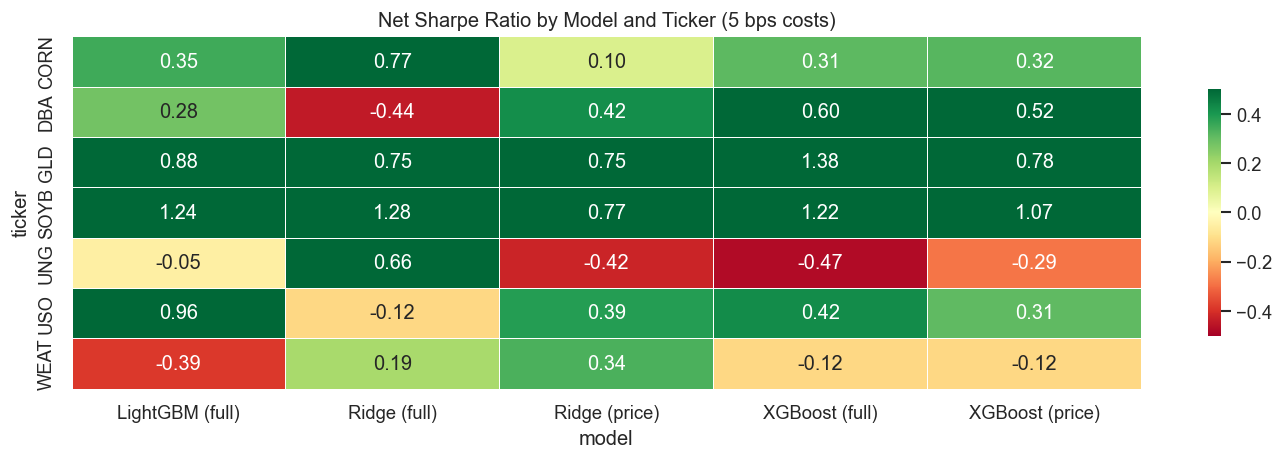

,sharpe_net,max_dd,ann_return,total_return
model,,,,
XGBoost (price),0.839,-0.7201,0.2744,66.5080
XGBoost (full),0.645,-0.8938,0.1978,6.0288
Ridge (full),0.643,-0.7987,0.2037,6.2699
LightGBM (full),0.598,-0.8152,0.1837,4.8221
Ridge (price),0.554,-0.8744,0.1741,9.7435


In [6]:
sharpe_pivot = summary.pivot(index="ticker", columns="model", values="sharpe_net")

fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(sharpe_pivot, annot=True, fmt=".2f", cmap="RdYlGn",
            center=0, vmin=-0.5, vmax=0.5, ax=ax,
            linewidths=0.5, cbar_kws={"shrink": 0.7})
ax.set_title("Net Sharpe Ratio by Model and Ticker (5 bps costs)")
plt.tight_layout()
plt.show()

# Portfolio-level summary
port_summary = []
for model_name, port in portfolios.items():
    r = port["portfolio_return"].dropna()
    ec = port["equity_curve"]
    port_summary.append({
        "model":        model_name,
        "sharpe_net":   round(sharpe_ratio(r), 3),
        "max_dd":       round(max_drawdown(ec), 4),
        "ann_return":   round(r.mean() * 252, 4),
        "total_return": round(ec.iloc[-1] - 1, 4),
    })
pd.DataFrame(port_summary).set_index("model").sort_values("sharpe_net", ascending=False)